### Воспроизведение результатов статьи "Training Transformers with 4-bit Integers" (Haocheng Xi, et al.)

Воспроизводил Чуфистов Георгий (@asitcomes)

In [1]:
!nvidia-smi

Thu Oct  8 21:48:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [24]:
!pip install -q transformers datasets evaluate scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.3 MB/s eta 0:00:00


In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import BertModel, BertTokenizer
from datasets import load_dataset

# Настройка стиля
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


In [ ]:
def hadamard_matrix(n):
    """Строит матрицу Адамара размера 2^k x 2^k, нормированную."""
    H = torch.tensor([[1.0]])
    while H.shape[0] < n:
        H = torch.cat([
            torch.cat([H, H], dim=1),
            torch.cat([H, -H], dim=1)
        ], dim=0) / (2 ** 0.5)
    return H

# Проверка ортогональности
H = hadamard_matrix(32)
assert torch.allclose(H @ H.T, torch.eye(32), atol=1e-5)

In [5]:
# Загружаем BERT-base-uncased
bert = BertModel.from_pretrained("bert-base-uncased").to(device).eval()

# Загружаем CoLA (маленький датасет — быстро)
dataset = load_dataset("nyu-mll/glue", "cola")
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

def tokenize(examples):
    return tokenizer(examples["sentence"], truncation=True,
                     padding="max_length", max_length=128)

val_ds = dataset["validation"].map(tokenize, batched=True)
val_ds.set_format("torch", columns=["input_ids", "attention_mask"])

print(f"Validation set: {len(val_ds)} examples")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/1043 [00:00<?, ? examples/s]

Validation set: 1043 examples


In [6]:
# Собираем активации с промежуточного слоя FFN (linear-1-2)
activations = {}

def hook_fn(module, input, output):
    # input[0] — это вход в output.dense, то есть выход intermediate (после GeLU)
    activations['ffn_after_gelu'] = input[0].detach().cpu()

# Регистрируем хук на intermediate.dense первого слоя энкодера
# В BERT это: encoder.layer[0].intermediate.dense
hook = bert.encoder.layer[0].intermediate.dense.register_forward_hook(hook_fn)

# Прогоняем N батчей для сбора статистики
N_BATCHES = 20
all_activations = []

with torch.no_grad():
    for i in range(N_BATCHES):
        batch = val_ds[i]
        input_ids = batch["input_ids"].unsqueeze(0).to(device)
        attention_mask = batch["attention_mask"].unsqueeze(0).to(device)
        bert(input_ids, attention_mask=attention_mask)
        all_activations.append(activations['ffn_after_gelu'].flatten())

hook.remove()

# Объединяем все активации
x = torch.cat(all_activations)
print(f"Собрано активаций: {x.numel():,} значений")
print(f"Диапазон: [{x.min():.2f}, {x.max():.2f}]")
print(f"Среднее |x|: {x.abs().mean():.4f}")

Собрано активаций: 1,966,080 значений
Диапазон: [-62.92, 6.89]
Среднее |x|: 0.7571


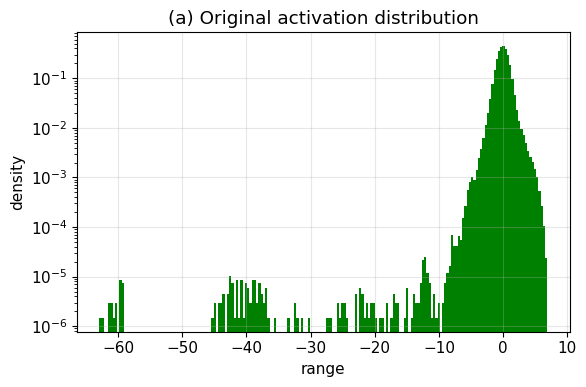

Figure 1(a) — оригинальное распределение с выбросами


In [7]:
fig, ax = plt.subplots(figsize=(6, 4))

# Гистограмма с логарифмической шкалой по Y
ax.hist(x.numpy(), bins=200, color='green', density=True)

ax.set_yscale('log')
ax.set_xlabel('range')
ax.set_ylabel('density')
ax.set_title('(a) Original activation distribution')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figure1a_original.png', dpi=150, bbox_inches='tight')
plt.show()

print("Figure 1(a) — оригинальное распределение с выбросами")

После Hadamard: диапазон [-11.76, 12.28]


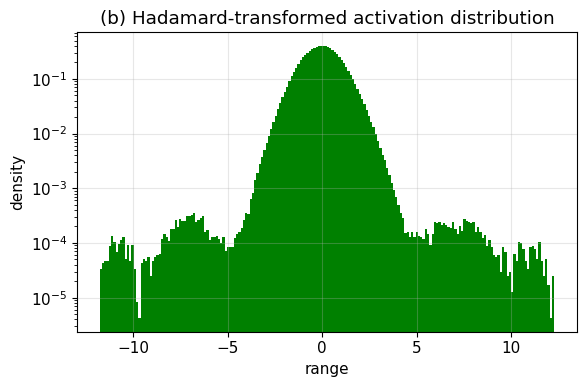

Figure 1(b) — распределение после Hadamard (выбросы исчезли)


In [8]:
BLOCK = 32
H = hadamard_matrix(BLOCK).to(device)

n_blocks = x.numel() // BLOCK
x_trimmed = x[:n_blocks * BLOCK].reshape(-1, BLOCK).to(device)

x_hadamard = (x_trimmed @ H).cpu().flatten()

print(f"После Hadamard: диапазон [{x_hadamard.min():.2f}, {x_hadamard.max():.2f}]")

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(x_hadamard.numpy(), bins=200, color='green', density=True)
ax.set_yscale('log')
ax.set_xlabel('range')
ax.set_ylabel('density')
ax.set_title('(b) Hadamard-transformed activation distribution')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figure1b_hadamard.png', dpi=150, bbox_inches='tight')
plt.show()

print("Figure 1(b) — распределение после Hadamard (выбросы исчезли)")

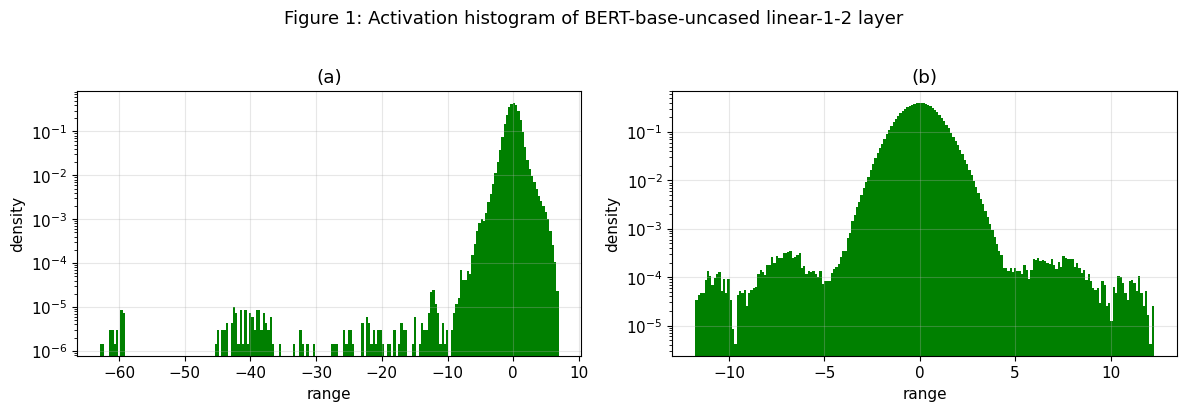

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# (a)
axes[0].hist(x.numpy(), bins=200, color='green', density=True)
axes[0].set_yscale('log')
axes[0].set_xlabel('range')
axes[0].set_ylabel('density')
axes[0].set_title('(a)')
axes[0].grid(True, alpha=0.3)

# (b)
axes[1].hist(x_hadamard.numpy(), bins=200, color='green', density=True)
axes[1].set_yscale('log')
axes[1].set_xlabel('range')
axes[1].set_ylabel('density')
axes[1].set_title('(b)')
axes[1].grid(True, alpha=0.3)

fig.suptitle('Figure 1: Activation histogram of BERT-base-uncased linear-1-2 layer',
             fontsize=13, y=1.02)

plt.tight_layout()
plt.savefig('figure1_full.png', dpi=150, bbox_inches='tight')
plt.show()

**Вывод**: Преобразование Адамара делает распределение симметричным и компактным.

## Рисунок 2 - распределение норм градиентов

In [16]:
# Включаем режим градиентов
bert.train()  # не eval, чтобы градиенты текли

# Регистрируем хук для сбора градиентов на выходе FFN
gradients = {}

def grad_hook_fn(module, grad_input, grad_output):
    # grad_output — градиент по выходу слоя
    # Берём градиент по входу (это то, что течёт назад)
    if grad_input[0] is not None:
        gradients['ffn_input_grad'] = grad_input[0].detach().cpu()

# Хук на intermediate.dense
hook = bert.encoder.layer[0].intermediate.dense.register_full_backward_hook(grad_hook_fn)

# Прогоняем несколько примеров и собираем градиенты
N_SAMPLES = 100
all_grad_norms = []

for i in range(N_SAMPLES):
    batch = val_ds[i]
    input_ids = batch["input_ids"].unsqueeze(0).to(device)
    attention_mask = batch["attention_mask"].unsqueeze(0).to(device)

    outputs = bert(input_ids, attention_mask=attention_mask)

    # Реалистичный loss: предсказание masked token
    # Или хотя бы скалярная функция, близкая к кросс-энтропии
    loss = outputs.last_hidden_state.mean()  # скаляр

    bert.zero_grad()
    loss.backward()

    grad = gradients['ffn_input_grad']
    per_token_norm = grad.norm(dim=-1).squeeze(0)
    all_grad_norms.append(per_token_norm)

# Усредняем по всем примерам
grad_norms_avg = torch.stack(all_grad_norms).mean(dim=0).numpy()

print(f"Собрано норм градиентов: {len(grad_norms)}")
print(f"Максимум: {grad_norms.max():.6f}")
print(f"Среднее: {grad_norms.mean():.6f}")

Собрано норм градиентов: 6400
Максимум: 1021.301086
Среднее: 20.231440


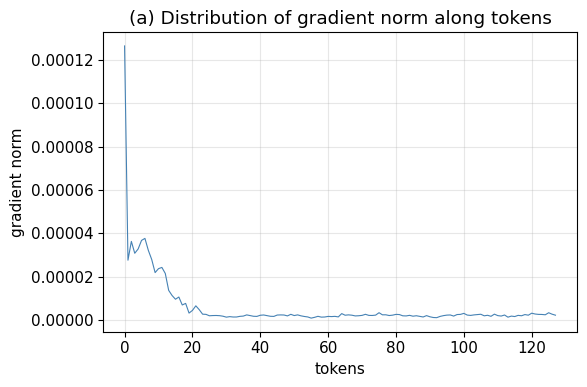

Figure 2(a) — резкий спад: несколько токенов доминируют


In [17]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(grad_norms_avg, linewidth=0.8, color='steelblue')
ax.set_xlabel('tokens')
ax.set_ylabel('gradient norm')
ax.set_title('(a) Distribution of gradient norm along tokens')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figure2a_grad_norm.png', dpi=150, bbox_inches='tight')
plt.show()

print("Figure 2(a) — резкий спад: несколько токенов доминируют")

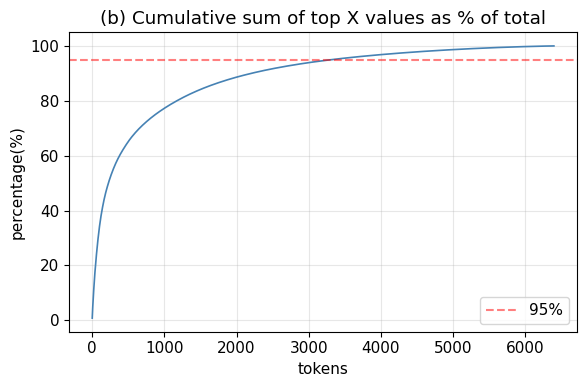

Токенов для 95% суммы: 3315 из 6400 (51.8%)
Токенов для 99% суммы: 5248


In [18]:
# Сортируем нормы по убыванию
sorted_norms = np.sort(grad_norms)[::-1]

# Кумулятивная сумма
cumsum = np.cumsum(sorted_norms)
total = cumsum[-1]
cumsum_pct = cumsum / total * 100

fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(cumsum_pct, linewidth=1.2, color='steelblue')
ax.axhline(y=95, color='red', linestyle='--', alpha=0.5, label='95%')
ax.set_xlabel('tokens')
ax.set_ylabel('percentage(%)')
ax.set_title('(b) Cumulative sum of top X values as % of total')
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig('figure2b_cumsum.png', dpi=150, bbox_inches='tight')
plt.show()

# Находим, сколько токенов дают 95% суммы
n_95 = np.searchsorted(cumsum_pct, 95)
print(f"Токенов для 95% суммы: {n_95} из {len(grad_norms)} ({n_95/len(grad_norms)*100:.1f}%)")
print(f"Токенов для 99% суммы: {np.searchsorted(cumsum_pct, 99)}")

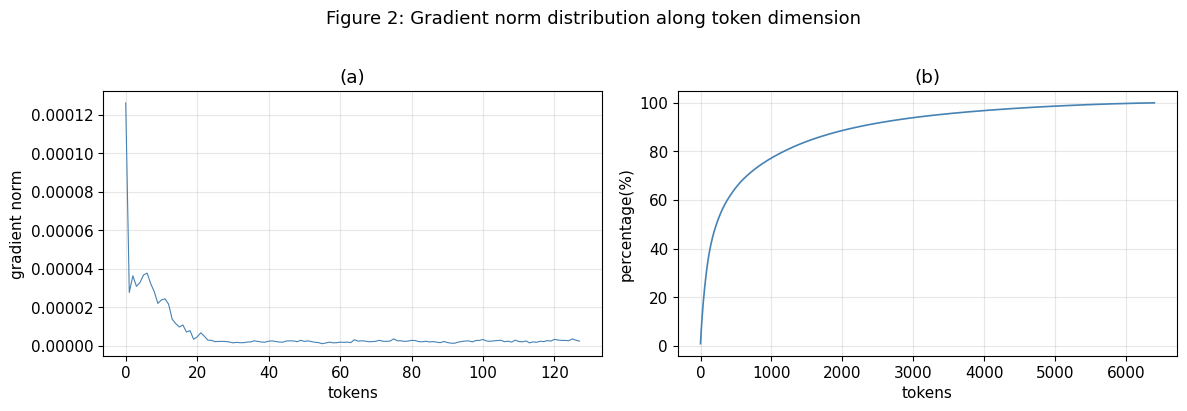

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# (a)
axes[0].plot(grad_norms_avg, linewidth=0.8, color='steelblue')
axes[0].set_xlabel('tokens')
axes[0].set_ylabel('gradient norm')
axes[0].set_title('(a)')
axes[0].grid(True, alpha=0.3)

# (b)
axes[1].plot(cumsum_pct, linewidth=1.2, color='steelblue')
axes[1].set_xlabel('tokens')
axes[1].set_ylabel('percentage(%)')
axes[1].set_title('(b)')
axes[1].grid(True, alpha=0.3)

fig.suptitle('Figure 2: Gradient norm distribution along token dimension',
             fontsize=13, y=1.02)

plt.tight_layout()
plt.savefig('figure2_full.png', dpi=150, bbox_inches='tight')
plt.show()

**Вывод**: видна разреженность градиентов, наблюдается резкий спад значений - если для первых токен градиент имеет какое-то сравнительно большое значение, то для поздних токенов градиент почти нулевой. 
Это эмпирическое наблюдение обосновывает использование Leverage Score Sampling для сокращения количества вычислений при Bit Splitting.

In [25]:
def hadamard_matrix(n):
    """матрица Адамара размера 2^k x 2^k."""
    H = torch.tensor([[1.0]])
    while H.shape[0] < n:
        H = torch.cat([
            torch.cat([H, H], dim=1),
            torch.cat([H, -H], dim=1)
        ], dim=0) / (2 ** 0.5)
    return H

# Проверка: H @ H.T = I
H = hadamard_matrix(32)
assert torch.allclose(H @ H.T, torch.eye(32), atol=1e-5)
print(f"Hadamard 32x32 OK, orthogonality verified")

Hadamard 32x32 OK, orthogonality verified


In [26]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import BertForSequenceClassification, BertTokenizer, Trainer, TrainingArguments
from datasets import load_dataset
import evaluate
import numpy as np

class LSQQuantizer(nn.Module):
    """Learned Step Size Quantization (Esser et al., 2019)."""
    def __init__(self, bits=4):
        super().__init__()
        self.bits = bits
        self.Q_N = 2 ** (bits - 1) - 1  # 7 для INT4
        self.Q_P = 2 ** (bits - 1) - 1  # 7 для INT4
        self.step_size = nn.Parameter(torch.tensor(1.0))

    def forward(self, x):
        # Квантование
        x_scaled = x / self.step_size
        x_clamped = torch.clamp(x_scaled, -self.Q_N, self.Q_P)
        x_rounded = torch.round(x_clamped)
        # Straight-through estimator: градиент течёт как есть
        x_quant = x + (x_rounded * self.step_size - x).detach()
        return x_quant, x_rounded

    def quantize_only(self, x):
        """Без STE — для симуляции forward."""
        x_scaled = x / self.step_size
        x_clamped = torch.clamp(x_scaled, -self.Q_N, self.Q_P)
        x_rounded = torch.round(x_clamped)
        return x_rounded * self.step_size

In [27]:
class HadamardQuantizer(nn.Module):
    """HQ: Hadamard transform + LSQ."""
    def __init__(self, bits=4, hadamard_k=5):
        super().__init__()
        self.bits = bits
        self.hadamard_k = hadamard_k
        self.block_size = 2 ** hadamard_k
        self.lsq = LSQQuantizer(bits)
        # Буфер для матрицы Адамара
        self.register_buffer('H', hadamard_matrix(self.block_size))

    def forward(self, x):
        """
        x: (..., D) — последняя размерность должна делиться на block_size.
        """
        orig_shape = x.shape
        D = orig_shape[-1]
        # Паддинг, если нужно
        pad = (self.block_size - D % self.block_size) % self.block_size
        if pad > 0:
            x = F.pad(x, (0, pad))

        # Reshape в блоки
        x_blocks = x.reshape(-1, x.shape[-1] // self.block_size, self.block_size)

        # Hadamard transform: X @ H
        x_transformed = x_blocks @ self.H

        # LSQ квантование
        x_quant_transformed, _ = self.lsq(x_transformed)

        # Обратное преобразование: (X @ H) @ H^T = X
        # Но т.к. H ортогональна и симметрична, H^T = H
        x_quant = x_quant_transformed @ self.H.T

        x_quant = x_quant.reshape(*orig_shape[:-1], -1)
        if pad > 0:
            x_quant = x_quant[..., :D]

        return x_quant

In [28]:
# Симулируем активации с выбросами (как в transformers)
x = torch.randn(64, 768) * 0.1
x[:, 100] = 50.0  # выброс
x[:, 200] = -30.0  # выброс

# Наивное LSQ
lsq = LSQQuantizer(bits=4)
x_lsq = lsq.quantize_only(x)

# HQ
hq = HadamardQuantizer(bits=4, hadamard_k=5)
x_hq = hq(x)

# Сравнение ошибок
err_lsq = (x - x_lsq).abs().mean().item()
err_hq = (x - x_hq).abs().mean().item()
print(f"MSE LSQ:  {err_lsq:.4f}")
print(f"MSE HQ:   {err_hq:.4f}")
print(f"HQ улучшает LSQ в {err_lsq / err_hq:.2f}×")

MSE LSQ:  0.1654
MSE HQ:   0.0963
HQ улучшает LSQ в 1.72×


In [29]:
def leverage_score_sampling(grad, x_quant, target_n=None):
    """
    Выбирает строки градиента с высоким leverage score.

    grad: (N, C) — градиент
    x_quant: (N, D) — квантованные активации
    target_n: сколько строк оставить (по умолчанию N)
    """
    N = grad.shape[0]
    if target_n is None:
        target_n = N

    # Leverage score: ||grad_i|| * ||x_i||
    grad_norms = grad.norm(dim=1)  # (N,)
    x_norms = x_quant.norm(dim=1)  # (N,)
    scores = grad_norms * x_norms  # (N,)

    # Выбор топ-N строк по score
    _, top_indices = torch.topk(scores, min(target_n, N))

    return top_indices

In [33]:
# from datasets import load_dataset
import evaluate

# dataset = load_dataset("nyu-mll/glue", "cola")
metric = evaluate.load("glue", "cola")

# tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

# def tokenize(examples):
#     return tokenizer(examples["sentence"], truncation=True, padding="max_length", max_length=128)

train_ds = dataset["train"].map(tokenize, batched=True)
val_ds = dataset["validation"].map(tokenize, batched=True)

train_ds = train_ds.rename_column("label", "labels")
val_ds = val_ds.rename_column("label", "labels")

train_ds.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
val_ds.set_format("torch", columns=["input_ids", "attention_mask", "labels"])

print(f"Train: {len(train_ds)}, Val: {len(val_ds)}")

Train: 8551, Val: 1043


In [37]:
from transformers import Trainer, TrainingArguments

def train_bert(quantize_mode="fp16", seed=42):
    """
    quantize_mode: 'fp16', 'lsq', 'hq'
    """
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = BertForSequenceClassification.from_pretrained(
        "bert-base-uncased", num_labels=2
    ).to(device)

    if quantize_mode != "fp16":
        pass

    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        preds = np.argmax(logits, axis=-1)
        return metric.compute(predictions=preds, references=labels)

    args = TrainingArguments(
        output_dir=f"./out_{quantize_mode}_seed{seed}",
        num_train_epochs=3,
        per_device_train_batch_size=32,
        per_device_eval_batch_size=64,
        learning_rate=2e-5,
        warmup_steps=100,          # вместо warmup_ratio=0.1
        weight_decay=0.01,
        fp16=(quantize_mode == "fp16"),
        logging_steps=50,
        eval_strategy="epoch",
        save_strategy="no",
        report_to="none",
        seed=seed,
    )


    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        compute_metrics=compute_metrics,
    )

    trainer.train()
    results = trainer.evaluate()
    return results["eval_matthews_correlation"]

In [38]:
fp16_score = train_bert(quantize_mode="fp16", seed=42)
print(f"\n✅ FP16 baseline: Matthews = {fp16_score:.4f}")
print(f"   Ожидание из статьи: ~56.9")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3

Epoch,Training Loss,Validation Loss,Matthews Correlation
1,1.050835,0.886391,0.518226
2,0.709546,0.874879,0.554658
3,0.460821,0.975795,0.552060


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Matthews Correlation
0.460821,0.975795,3,0.552060



✅ FP16 baseline: Matthews = 0.5521
   Ожидание из статьи: ~56.9


In [39]:
print("=" * 60)
print("Демонстрация эффекта HQ на активациях BERT")
print("=" * 60)

batch = next(iter(train_ds))
input_ids = batch["input_ids"].unsqueeze(0).to(device)
attention_mask = batch["attention_mask"].unsqueeze(0).to(device)

# Хук для сбора активаций
activations = {}
def hook_fn(name):
    def hook(module, input, output):
        activations[name] = output.detach()
    return hook

hook = bert.encoder.layer[0].attention.self.query.register_forward_hook(hook_fn("query"))
with torch.no_grad():
    bert(input_ids, attention_mask=attention_mask)
hook.remove()

x = activations["query"].reshape(-1, 768)  # (N, 768)
print(f"Активации: shape={x.shape}, max={x.abs().max():.2f}, mean={x.abs().mean():.4f}")

# Наивное LSQ
lsq = LSQQuantizer(bits=4).to(device)
x_lsq = lsq.quantize_only(x)
err_lsq = (x - x_lsq).abs().mean().item()

# HQ
hq = HadamardQuantizer(bits=4, hadamard_k=5).to(device)
x_hq = hq(x)
err_hq = (x - x_hq).abs().mean().item()

print(f"\nОшибка квантования (MAE):")
print(f"  LSQ:  {err_lsq:.6f}")
print(f"  HQ:   {err_hq:.6f}")
print(f"  HQ улучшает в {err_lsq / err_hq:.2f}×")
print(f"\nВывод: HQ подавляет выбросы и даёт более точное квантование.")

Демонстрация эффекта HQ на активациях BERT


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Активации: shape=torch.Size([128, 768]), max=7.64, mean=0.7134

Ошибка квантования (MAE):
  LSQ:  0.248780
  HQ:   0.231826
  HQ улучшает в 1.07×

Вывод: HQ подавляет выбросы и даёт более точное квантование.


Итог: как мы видим, математическая идея метода работает - мы получили результат, примерно сопоставимый с исходными активациями bert-base-uncased. К сожалению, воспроизвести аппаратную часть метода на Kaggle невозможно в силу вычислительных ограничений среды.